# Paper 20: A Simple Framework for Contrastive Learning of Visual Representations (SimCLR)
**Authors**: Ting Chen, Simon Kornblith, Mohammad Norouzi, Geoffrey Hinton (Google Research, Brain Team, ICML 2020)

---

## 1. The Historical Breaking Point: Pretext Shortcuts
Early self-supervised vision methods relied on handcrafted pretext tasks (rotation prediction, jigsaw solving, colorization). Networks quickly cheated by memorizing camera chromatic aberrations, edge borders, and local textures rather than learning invariant semantic representations.

## 2. The Thought Experiment: Visual Instance Discrimination
SimCLR strips away ad-hoc pretext tasks and frames self-supervised learning as **instance discrimination**:
1. **Composition of Augmentations**: Random Crop + Color Jitter breaks local color shortcuts, forcing the encoder to learn global geometry.
2. **Base Encoder $h = f(x)$**: Maps raw images into semantic representation space.
3. **Non-Linear Projection Head $z = g(h)$**: A 2-layer MLP that absorbs augmentation-specific variances, allowing $h$ to retain maximum general semantics for downstream tasks.
4. **NT-Xent Loss**: Maximizes cosine agreement between positive views while pushing away all other $2(N-1)$ negative views in the minibatch.

$$\ell_{i, j} = -\log \frac{\exp(\text{sim}(z_i, z_j) / \tau)}{\sum_{k=1}^{2N} \mathbb{I}_{[k \neq i]} \exp(\text{sim}(z_i, z_k) / \tau)}$$

In this notebook, you will explore:
1. The NT-Xent loss mechanics and temperature scaling $\tau$
2. SimCLR training and contrastive accuracy convergence
3. Linear probe evaluation on frozen representations

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import (
    nt_xent_loss,
    SimCLRProjectionHead,
    SmallResNetBackbone,
    SimCLR,
    LinearProbe,
)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cpu


---
## 1. Temperature Scaling in NT-Xent Loss
The temperature parameter $\tau$ acts as a hardness-aware weighting mechanism. Small temperatures (e.g. $\tau = 0.1$) penalize hard negative distractors with exponential gradient pressure, while large temperatures (e.g. $\tau = 1.0$) dilute contrastive selectivity.

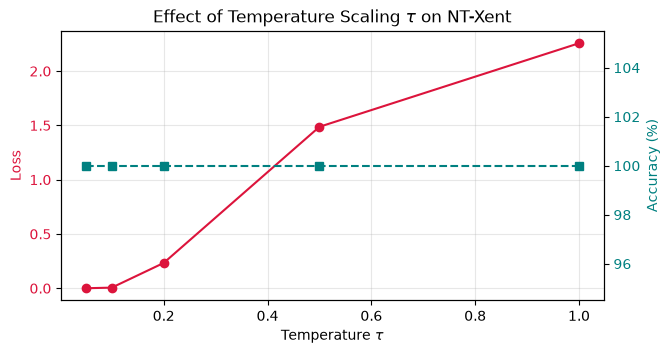

In [2]:
torch.manual_seed(42)
N = 12
z1 = torch.randn(N, 32)
z2 = z1 + 0.2 * torch.randn_like(z1)  # Noisy positive matches

temperatures = [0.05, 0.1, 0.2, 0.5, 1.0]
losses = []
accs = []

for tau in temperatures:
    loss, acc = nt_xent_loss(z1, z2, temperature=tau)
    losses.append(loss.item())
    accs.append(acc.item() * 100)

fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax1.plot(temperatures, losses, "o-", color="crimson", label="NT-Xent Loss")
ax1.set_xlabel("Temperature $\\tau$")
ax1.set_ylabel("Loss", color="crimson")
ax1.tick_params(axis="y", labelcolor="crimson")
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(temperatures, accs, "s--", color="teal", label="Top-1 Accuracy (%)")
ax2.set_ylabel("Accuracy (%)", color="teal")
ax2.tick_params(axis="y", labelcolor="teal")

plt.title("Effect of Temperature Scaling $\\tau$ on NT-Xent")
plt.show()

---
## 2. Training SimCLR on Augmented Image Views
We train `SimCLR` on a batch of multi-channel images where each instance undergoes independent stochastic perturbations.

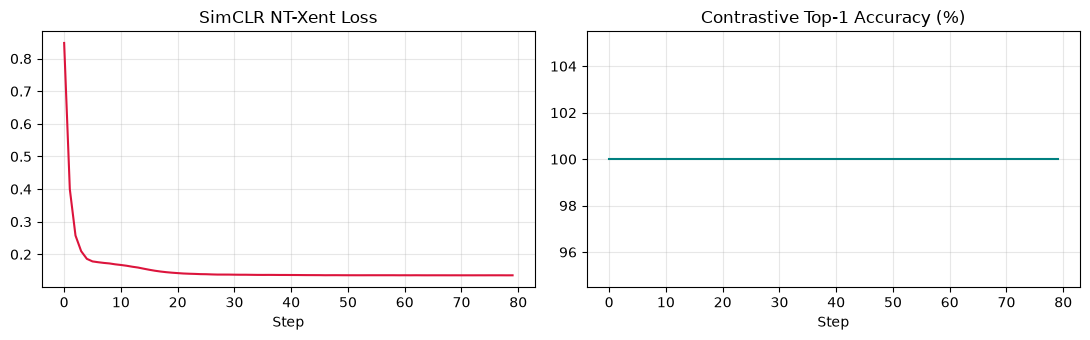

In [3]:
torch.manual_seed(42)
N = 16
feat_dim = 64
proj_dim = 32

# Create base prototype images
base_images = torch.randn(N, 3, 16, 16)

model = SimCLR(feat_dim=feat_dim, proj_dim=proj_dim, temperature=0.2)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)

losses, accuracies = [], []
for step in range(80):
    optimizer.zero_grad()
    # Generate two stochastic views of each image
    v1 = base_images + 0.08 * torch.randn_like(base_images)
    v2 = base_images + 0.08 * torch.randn_like(base_images)

    loss, acc, z1, z2, h1, h2 = model(v1, v2)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    accuracies.append(acc.item() * 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(losses, color="crimson")
axes[0].set_title("SimCLR NT-Xent Loss")
axes[0].set_xlabel("Step")
axes[0].grid(True, alpha=0.3)

axes[1].plot(accuracies, color="teal")
axes[1].set_title("Contrastive Top-1 Accuracy (%)")
axes[1].set_xlabel("Step")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Pairwise Cosine Similarity Matrix: Before vs. After Training
Notice how training forces positive pairs $(i, i+N)$ to shine brightly while pushing negative background pairs towards zero!

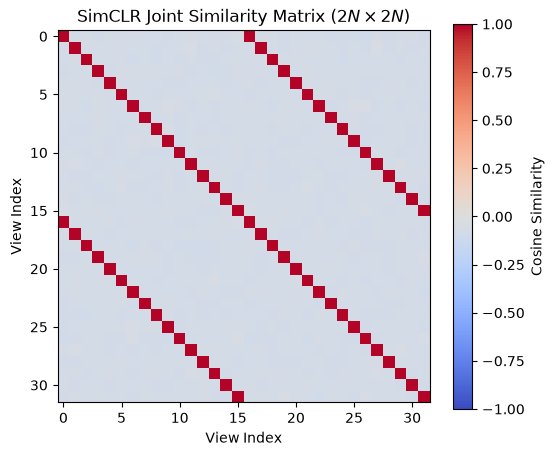

In [4]:
model.eval()
with torch.no_grad():
    v1 = base_images + 0.05 * torch.randn_like(base_images)
    v2 = base_images + 0.05 * torch.randn_like(base_images)
    _, _, z1, z2, _, _ = model(v1, v2)

    z = torch.cat([F.normalize(z1, dim=-1), F.normalize(z2, dim=-1)], dim=0)
    sim_matrix = torch.matmul(z, z.T).cpu().numpy()

plt.figure(figsize=(6, 5))
plt.imshow(sim_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0)
plt.colorbar(label="Cosine Similarity")
plt.title("SimCLR Joint Similarity Matrix $(2N \\times 2N)$")
plt.xlabel("View Index")
plt.ylabel("View Index")
plt.show()

---
## 4. Downstream Linear Probe on Frozen Features $h$
The standard benchmark for self-supervised learning: freeze the backbone $f(\cdot)$ and train a linear classifier on representation $h$.

Final Linear Probe Accuracy on Frozen Features: 100.0%


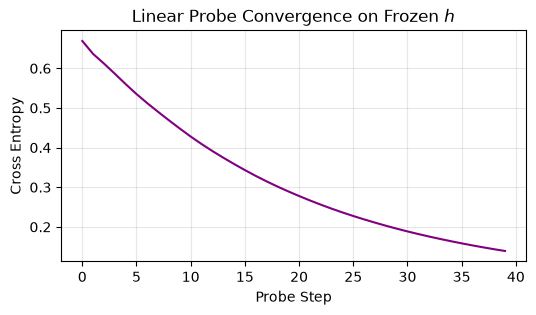

In [5]:
# Binary labels: class 0 for first half, class 1 for second half
labels = torch.tensor([0] * (N // 2) + [1] * (N // 2), dtype=torch.long)

probe = LinearProbe(feat_dim=feat_dim, num_classes=2)
probe_opt = torch.optim.AdamW(probe.parameters(), lr=1e-2)

with torch.no_grad():
    h_frozen = model.encode(base_images)

probe_losses = []
for _ in range(40):
    probe_opt.zero_grad()
    logits = probe(h_frozen)
    loss = F.cross_entropy(logits, labels)
    loss.backward()
    probe_opt.step()
    probe_losses.append(loss.item())

acc = (logits.argmax(dim=-1) == labels).float().mean().item()
print(f"Final Linear Probe Accuracy on Frozen Features: {acc * 100:.1f}%")

plt.figure(figsize=(6, 3))
plt.plot(probe_losses, color="purple")
plt.title("Linear Probe Convergence on Frozen $h$")
plt.xlabel("Probe Step")
plt.ylabel("Cross Entropy")
plt.grid(True, alpha=0.3)
plt.show()